# 05 - Evaluation summary

Goal: compare the 4 trained models on the **same test images**, next to the ground truth.

1. SimpleUNet
2. SimpleUNet2
3. UNet++
4. Pretrained UNet++

We do not train anything here. We only load the saved `.pth` files and look at the results.

## Step 1 - Imports

In [1]:
import os
import random
import sys

import numpy as np
import torch
import matplotlib.pyplot as plt

## Step 2 - Project folder and our own code

In [2]:
# Colab: use Google Drive, local: use the current folder
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = "/content/drive/MyDrive/Colab Notebooks/Deep_learning_course/Final_project/PanNuke"
except ImportError:
    PROJECT_DIR = os.getcwd()

sys.path.insert(0, PROJECT_DIR)

# the same files we used in notebooks 01-04
from pannuke_dataset import PanNukeDataset
from pannuke_utils import *
from model_simple_unet import SimpleUNet
from model_simple_unet2 import SimpleUNet2
from model_unet_plusplus import UNetPlusPlus
from model_pretrained_unet_plusplus import create_pretrained_unetplusplus

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", DEVICE)

C:\Projects\MachineLearning\DeepLearning_Cubix\FinalProject\PanNuke\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu


## Step 3 - Load the data and find the test images

In notebooks 01-04 we used `SEED = 54` and `random.shuffle`, so every model got the **same** test images.
If we repeat the same steps here, we get exactly those test images again.

In [3]:
images = np.load(PROJECT_DIR + "/data_root/images.npy")
masks = np.load(PROJECT_DIR + "/data_root/masks.npy")

# same seed and same shuffle as in notebooks 01-04
random.seed(54)
indices = list(range(len(images)))
random.shuffle(indices)

n_val = int(len(images) * 0.15)
n_test = int(len(images) * 0.15)
test_idx = indices[n_val : n_val + n_test]

print("Number of test images:", len(test_idx))

Number of test images: 398


## Step 4 - Test datasets

The three models we trained from scratch use plain `[0, 1]` images (`"simple"`).
The pretrained model needs ImageNet normalization (`"imagenet"`), like in notebook 04.

In [4]:
test_data_simple = PanNukeDataset(images, masks, augment=False, normalization="simple")
test_data_imagenet = PanNukeDataset(images, masks, augment=False, normalization="imagenet")

Dataset ready: 2656 samples
Dataset ready: 2656 samples


## Step 5 - Load the 4 models

For each model: create the empty model, then load the saved weights from the `.pth` file.

In [5]:
CHECKPOINT_DIR = PROJECT_DIR + "/checkpoint_dir"

def load_model(model, file_name):
    checkpoint = torch.load(CHECKPOINT_DIR + "/" + file_name, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(DEVICE)
    model.eval()
    print(f"{file_name}: epoch {checkpoint['epoch']}, val Dice {checkpoint['val_dice']:.4f}")
    return model

model_1 = load_model(SimpleUNet(num_classes=6), "SimpleUNet_30.pth")
model_2 = load_model(SimpleUNet2(num_classes=6), "SimpleUnet2_113.pth")
model_3 = load_model(UNetPlusPlus(num_classes=6), "UNetPlusPlus_best_result_142.pth")
model_4 = load_model(create_pretrained_unetplusplus(), "PreTrained_UNetPlusPlus_75.pth")

SimpleUNet_30.pth: epoch 31, val Dice 0.4898
SimpleUnet2_113.pth: epoch 114, val Dice 0.5262
UNetPlusPlus_best_result_142.pth: epoch 143, val Dice 0.5620
PreTrained_UNetPlusPlus_75.pth: epoch 76, val Dice 0.6584


## Step 6 - Compare the models on 15 test images

One row = one test image. Columns: original image, ground truth, then the 4 models.
All models see the **same** images, so the columns can be compared directly.

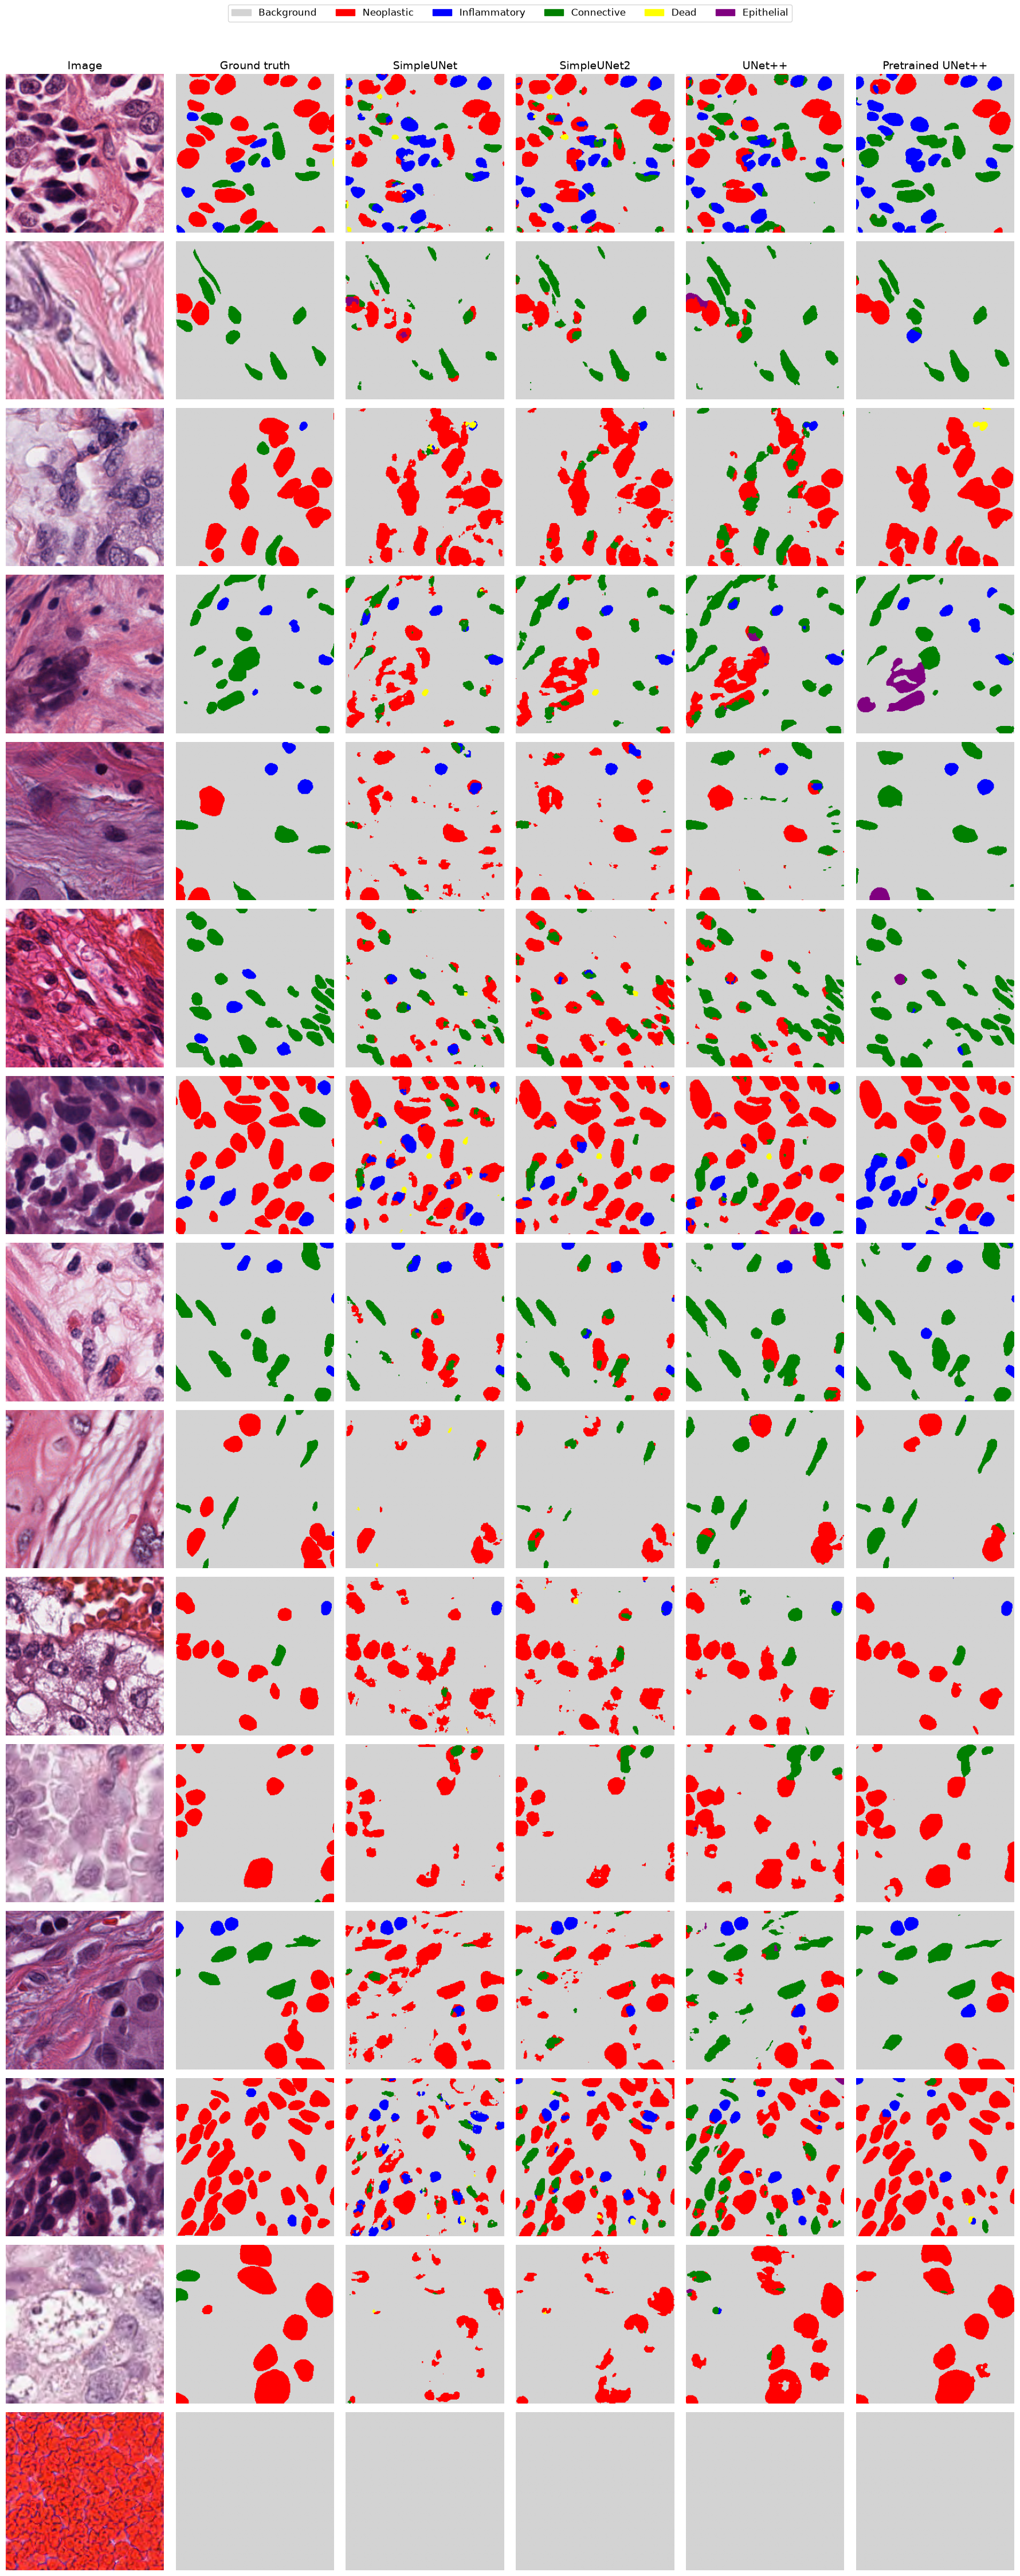

In [6]:
import matplotlib.patches as mpatches

num_images = 15
column_titles = ["Image", "Ground truth", "SimpleUNet", "SimpleUNet2", "UNet++", "Pretrained UNet++"]

# run one image through one model and return the predicted class map
def predict(model, image):
    with torch.no_grad():
        output = model(image.unsqueeze(0).to(DEVICE))
    return torch.argmax(output, dim=1).squeeze(0).cpu().numpy()

fig, axes = plt.subplots(num_images, 6, figsize=(18, num_images * 3))

for row in range(num_images):
    idx = test_idx[row]                          # position in the full dataset

    image, mask = test_data_simple[idx]          # input for the 3 models trained from scratch
    image_imagenet, _ = test_data_imagenet[idx]  # input for the pretrained model

    original = images[idx].astype(np.uint8)      # the original picture, for display

    panels = [
        original,
        mask.numpy(),                            # ground truth
        predict(model_1, image),
        predict(model_2, image),
        predict(model_3, image),
        predict(model_4, image_imagenet),
    ]

    for col in range(6):
        ax = axes[row, col]
        if col == 0:
            ax.imshow(panels[col])
        else:
            ax.imshow(panels[col], cmap=custom_cmap, vmin=0, vmax=5)
        ax.axis("off")
        if row == 0:
            ax.set_title(column_titles[col], fontsize=14)

# legend with the class colors
patches = [mpatches.Patch(color=COLORS[i], label=CATEGORY_NAMES[i]) for i in range(6)]
fig.legend(handles=patches, loc="upper center", ncol=6, fontsize=12)

plt.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

## Step 7 - Test Dice for each model

For every test image we compute the Dice score (the same `mean_dice` function is used as during training),
then take the average over all 398 test images.

Same images, same metric, same code for all 4 models, so the numbers can be compared directly.

In [7]:
# Dice score of one model on all 398 test images
# (uses the predict() function from Step 6, so run that cell first)
def test_dice(model, dataset):
    scores = []
    for idx in test_idx:
        image, mask = dataset[idx]
        prediction = predict(model, image)
        scores.append(mean_dice(prediction, mask.numpy(), 6))
    return np.mean(scores)

results = {
    "SimpleUNet":        test_dice(model_1, test_data_simple),
    "SimpleUNet2":       test_dice(model_2, test_data_simple),
    "UNet++":            test_dice(model_3, test_data_simple),
    "Pretrained UNet++": test_dice(model_4, test_data_imagenet),   # needs ImageNet normalization
}

print(f"{'Model':<20}{'Test Dice':>10}")
print("-" * 30)
for name, dice in results.items():
    print(f"{name:<20}{dice:>10.4f}")

Model                Test Dice
------------------------------
SimpleUNet              0.4159
SimpleUNet2             0.4551
UNet++                  0.4806
Pretrained UNet++       0.6266
